# Modeling

1. Baseline every model on all features, scored with 5 fold CV on the training split.
2. Look at which features the trees and the logistic model lean on.
3. Re-run the same models on the top features only.

`X_test` is not touched here. Tuning and the final test score go in `06_evaluation_and_tuning`.

In [1]:
import sys, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from utils.preprocessing import drop_leaks, feature_names, make_pipeline

pd.set_option("display.width", 150)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
SEED = 42

In [2]:
processed_dir = PROJECT_ROOT / "data" / "Processed-Data"

# Load the cleaned dataset produced by 02
clean_df = pd.read_csv(
    processed_dir / "DSI_kickstarterscrape_dataset_cleaned.csv"
)

# Load the official split membership created by 03
train_split = pd.read_csv(
    processed_dir / "train_project_ids.csv"
)

test_split = pd.read_csv(
    processed_dir / "test_project_ids.csv"
)

# Reconstruct the exact same train/test partitions from the cleaned data
clean_by_id = clean_df.set_index("project id", drop=False)

train_rows = clean_by_id.loc[train_split["project id"]].copy()
test_rows = clean_by_id.loc[test_split["project id"]].copy()

# Targets were already saved with the official split
y_train = train_split["target"].astype(int).reset_index(drop=True)
y_test = test_split["target"].astype(int).reset_index(drop=True)

# Sanity-check that the saved targets still match campaign status
assert np.array_equal(
    train_rows["status"].eq("successful").astype(int).to_numpy(),
    y_train.to_numpy(),
)

assert np.array_equal(
    test_rows["status"].eq("successful").astype(int).to_numpy(),
    y_test.to_numpy(),
)

# Status is the target source, so it must not be a model feature
X_train = train_rows.drop(columns=["status"]).reset_index(drop=True)
X_test = test_rows.drop(columns=["status"]).reset_index(drop=True)

# Remove post-launch leakage columns, same as the original 05 workflow
X_train = drop_leaks(X_train)
X_test = drop_leaks(X_test)

# Verify exact split membership
assert X_train["project id"].tolist() == train_split["project id"].tolist()
assert X_test["project id"].tolist() == test_split["project id"].tolist()

assert set(X_train["project id"]).isdisjoint(
    set(X_test["project id"])
)

print(
    f"train {X_train.shape}   "
    f"test {X_test.shape}   "
    f"base rate {y_train.mean():.3f}"
)
print("columns:", X_train.columns.tolist())

train (29288, 11)   test (12553, 11)   base rate 0.547
columns: ['project id', 'name', 'url', 'category', 'subcategory', 'location', 'goal', 'funded date', 'levels', 'reward levels', 'duration']


## 1. Baseline on all features

Same pipeline for every model. Everything that learns from the data sits inside it, so the CV
folds stay clean.

In [3]:
CV = StratifiedKFold(5, shuffle=True, random_state=SEED)
SCORING = ["roc_auc", "accuracy", "f1", "average_precision"]


def run_experiments(models, X, y, keep=None, label="", cv=CV):
    "Cross validate each model and return one row per model."
    rows = []
    for name, model in models.items():
        pipe = make_pipeline(model, keep=keep)
        cvres = cross_validate(pipe, X, y, cv=cv, scoring=SCORING, n_jobs=-1)
        row = {"model": name, "features": label}
        for s in SCORING:
            row[s] = cvres[f"test_{s}"].mean()
        row["auc_std"] = cvres["test_roc_auc"].std()
        row["fit_sec"] = cvres["fit_time"].mean()
        rows.append(row)
    return pd.DataFrame(rows).set_index("model").sort_values("roc_auc", ascending=False)


MODELS = {
    "dummy (majority)": DummyClassifier(strategy="prior"),
    "logistic": LogisticRegression(max_iter=2000, C=1.0),
    "knn (k=25)": KNeighborsClassifier(n_neighbors=25, n_jobs=-1),
    "decision tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=SEED),
    "random forest": RandomForestClassifier(
        n_estimators=400, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    "hist gradient boosting": HistGradientBoostingClassifier(
        max_iter=400, learning_rate=0.06, random_state=SEED),
}

exp_all = run_experiments(MODELS, X_train, y_train, label="all features")
exp_all.round(4)

,features,roc_auc,accuracy,f1,average_precision,auc_std,fit_sec
model,,,,,,,
hist gradient boosting,all features,0.7674,0.7068,0.7493,0.7748,0.0041,2.3830
random forest,all features,0.7650,0.7037,0.7462,0.7729,0.0022,9.3396
logistic,all features,0.7649,0.7046,0.7415,0.7687,0.0042,3.9060
decision tree,all features,0.7292,0.6796,0.7275,0.7319,0.0052,1.4727
knn (k=25),all features,0.6964,0.6551,0.7208,0.6976,0.0043,1.3457
dummy (majority),all features,0.5000,0.5474,0.7075,0.5474,0.0000,1.4440


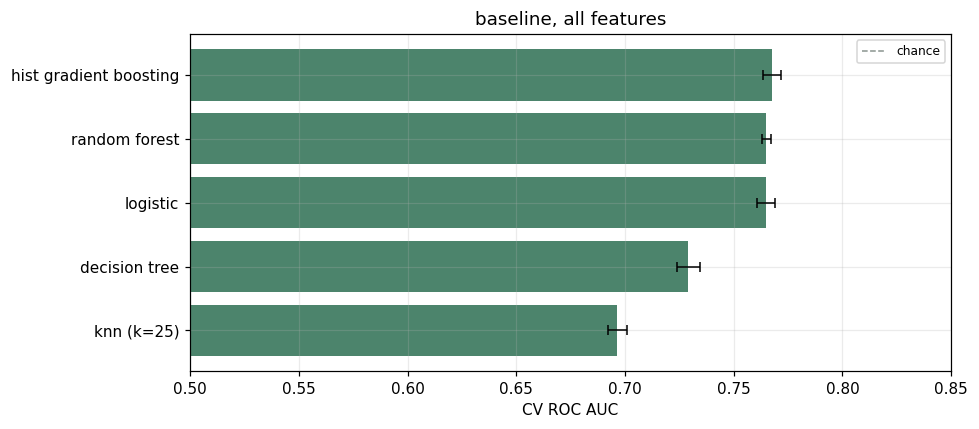

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
d = exp_all.drop(index="dummy (majority)").sort_values("roc_auc")
ax.barh(d.index, d["roc_auc"], xerr=d["auc_std"], color="#2c6f52", alpha=0.85,
        error_kw=dict(ecolor="k", capsize=3, lw=1))
ax.axvline(0.5, color="#8a9590", ls="--", lw=1, label="chance")
ax.set_xlim(0.5, 0.85); ax.set_xlabel("CV ROC AUC"); ax.legend(fontsize=8)
ax.set_title("baseline, all features")
plt.tight_layout()

## 2. Feature Importance/ Coefficients


In [5]:
rf = make_pipeline(RandomForestClassifier(
    n_estimators=400, min_samples_leaf=5, n_jobs=-1, random_state=SEED)).fit(X_train, y_train)
gb = make_pipeline(HistGradientBoostingClassifier(
    max_iter=400, learning_rate=0.06, random_state=SEED)).fit(X_train, y_train)
lr = make_pipeline(LogisticRegression(max_iter=2000)).fit(X_train, y_train)

names = feature_names(rf)
imp = pd.DataFrame({
    "random forest": rf.named_steps["model"].feature_importances_,
    "logistic |coef|": np.abs(lr.named_steps["model"].coef_[0]),
}, index=names)
imp["logistic coef"] = lr.named_steps["model"].coef_[0]

# rank them so the two scales can be compared
imp["rf rank"] = imp["random forest"].rank(ascending=False)
imp["lr rank"] = imp["logistic |coef|"].rank(ascending=False)
imp["mean rank"] = imp[["rf rank", "lr rank"]].mean(axis=1)
imp.sort_values("mean rank").head(20).round(4)

,random forest,logistic |coef|,logistic coef,rf rank,lr rank,mean rank
goal_per_tier,0.0924,1.8303,-1.8303,1.0,3.0,2.0
te_state,0.0560,4.2926,4.2926,4.0,1.0,2.5
te_subcategory,0.0742,3.8765,3.8765,3.0,2.0,2.5
backers_needed,0.0884,0.7979,0.7979,2.0,4.0,3.0
goal_vs_subcat,0.0469,0.5145,-0.5145,7.0,8.0,7.5
te_category,0.0468,0.5188,0.5188,8.0,7.0,7.5
goal_per_day,0.0471,0.5089,-0.5089,6.0,9.0,7.5
log_goal,0.0414,0.5831,0.5831,11.0,6.0,8.5
entry_vs_goal,0.0359,0.7132,-0.7132,13.0,5.0,9.0
duration,0.0434,0.3838,-0.3838,10.0,12.0,11.0


In [6]:
# impurity importance is biased, permutation importance is better but more computationally expensive
# Link article for source
perm = permutation_importance(gb, X_train, y_train, scoring="roc_auc",
                              n_repeats=3, random_state=SEED, n_jobs=-1)
pd.Series(perm.importances_mean, index=X_train.columns).sort_values(ascending=False).round(4)


goal             0.1578
reward levels    0.1238
duration         0.0298
name             0.0145
funded date      0.0075
subcategory      0.0047
url              0.0009
location         0.0007
category         0.0006
project id       0.0000
levels           0.0000
dtype: float64

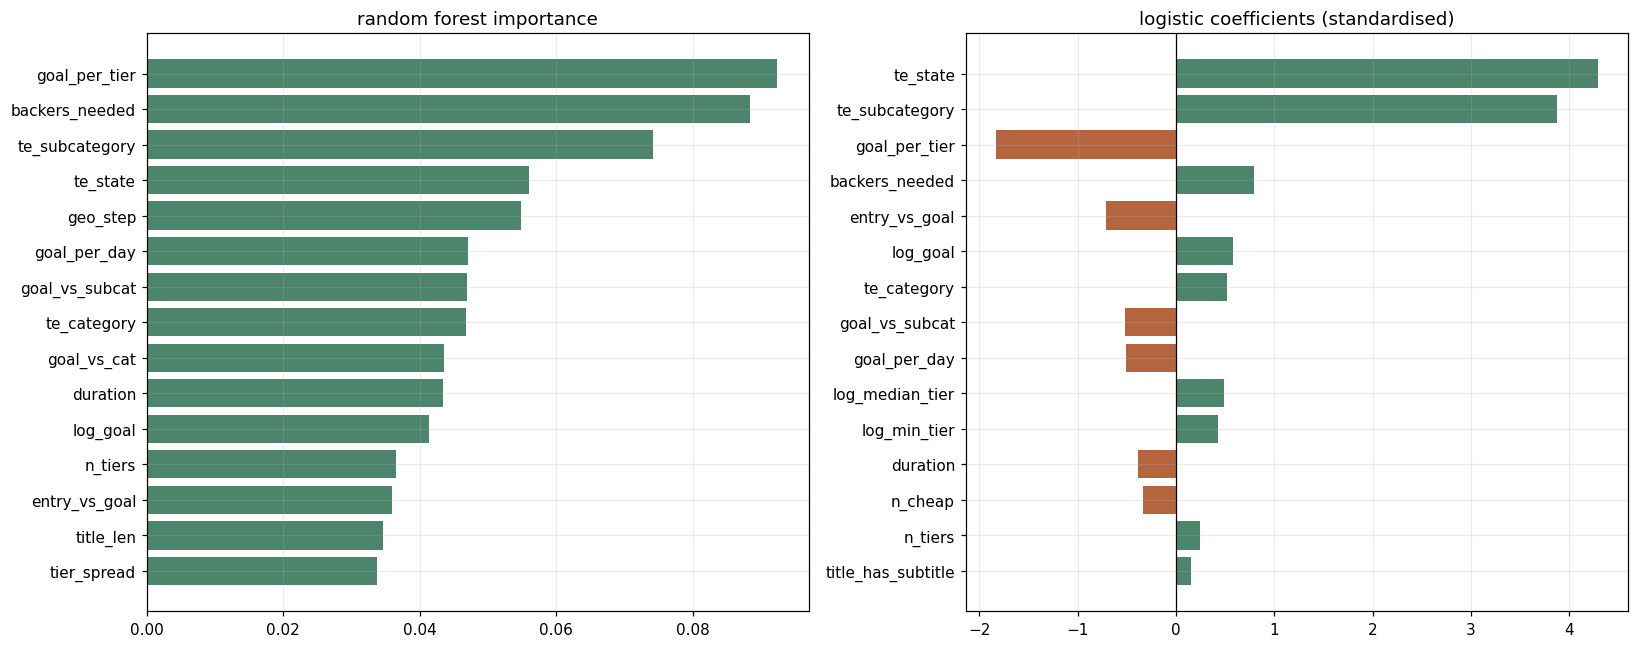

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top_rf = imp["random forest"].sort_values().tail(15)
axes[0].barh(top_rf.index, top_rf.values, color="#2c6f52", alpha=0.85)
axes[0].set_title("random forest importance")

top_lr = imp["logistic coef"].reindex(imp["logistic |coef|"].sort_values().tail(15).index)
axes[1].barh(top_lr.index, top_lr.values,
             color=["#a84a1c" if v < 0 else "#2c6f52" for v in top_lr.values], alpha=0.85)
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_title("logistic coefficients (standardised)")
plt.tight_layout()

The two rankings mostly agree at the top. Goal and its variants come first, then the encoded
subcategory, then the reward ladder. The signs make sense: bigger ask and longer duration push
down, more tiers and a cheap entry push up.

In [8]:
TOP_K = 12
top_features = imp.sort_values("mean rank").head(TOP_K).index.tolist()
print(f"top {TOP_K} by mean rank:")
for f in top_features:
    print("  ", f)

top 12 by mean rank:
   goal_per_tier
   te_state
   te_subcategory
   backers_needed
   goal_vs_subcat
   te_category
   goal_per_day
   log_goal
   entry_vs_goal
   duration
   log_median_tier
   n_tiers


## 3. Baseline models with top features only

In [9]:
exp_top = run_experiments(MODELS, X_train, y_train, keep=top_features, label=f"top {TOP_K}")
exp_top.round(4)

,features,roc_auc,accuracy,f1,average_precision,auc_std,fit_sec
model,,,,,,,
hist gradient boosting,top 12,0.7635,0.7036,0.7471,0.7702,0.0053,1.7372
random forest,top 12,0.7582,0.6999,0.7415,0.7644,0.0023,8.5047
logistic,top 12,0.7558,0.6968,0.7359,0.7590,0.0042,1.7293
decision tree,top 12,0.7327,0.6838,0.7329,0.7358,0.0056,1.5280
knn (k=25),top 12,0.7263,0.6786,0.7289,0.7209,0.0021,1.6036
dummy (majority),top 12,0.5000,0.5474,0.7075,0.5474,0.0000,1.3946


In [10]:
compare = pd.concat([
    exp_all[["roc_auc", "accuracy", "auc_std"]].add_suffix(" (all)"),
    exp_top[["roc_auc", "accuracy", "auc_std"]].add_suffix(f" (top {TOP_K})"),
], axis=1)
compare["auc delta"] = compare[f"roc_auc (top {TOP_K})"] - compare["roc_auc (all)"]
compare.sort_values(f"roc_auc (top {TOP_K})", ascending=False).round(4)

,roc_auc (all),accuracy (all),auc_std (all),roc_auc (top 12),accuracy (top 12),auc_std (top 12),auc delta
model,,,,,,,
hist gradient boosting,0.7674,0.7068,0.0041,0.7635,0.7036,0.0053,-0.0039
random forest,0.7650,0.7037,0.0022,0.7582,0.6999,0.0023,-0.0069
logistic,0.7649,0.7046,0.0042,0.7558,0.6968,0.0042,-0.0091
decision tree,0.7292,0.6796,0.0052,0.7327,0.6838,0.0056,0.0035
knn (k=25),0.6964,0.6551,0.0043,0.7263,0.6786,0.0021,0.0299
dummy (majority),0.5000,0.5474,0.0000,0.5000,0.5474,0.0000,0.0000


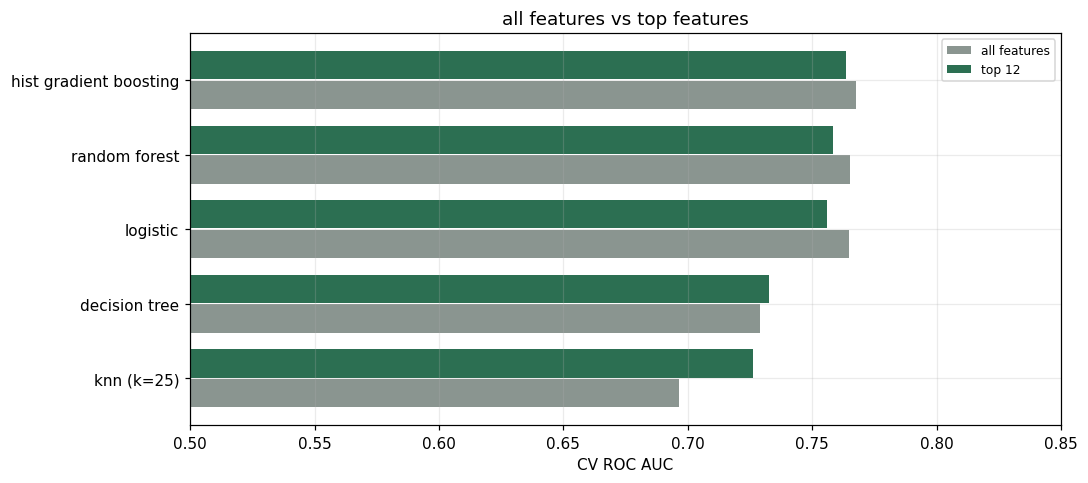

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
d = compare.drop(index="dummy (majority)").sort_values("roc_auc (all)")
y_pos = np.arange(len(d))
ax.barh(y_pos - 0.2, d["roc_auc (all)"], height=0.38, color="#8a9590", label="all features")
ax.barh(y_pos + 0.2, d[f"roc_auc (top {TOP_K})"], height=0.38, color="#2c6f52",
        label=f"top {TOP_K}")
ax.set_yticks(y_pos); ax.set_yticklabels(d.index)
ax.set_xlim(0.5, 0.85); ax.set_xlabel("CV ROC AUC"); ax.legend(fontsize=8)
ax.set_title("all features vs top features")
plt.tight_layout()

## Summary

**Baseline.** Boosting 0.767, random forest 0.765, logistic 0.765. Those three are within a
standard deviation of each other, so maybe further tuning or feature engineering could help choose a winner. Decision tree 0.729 and kNN 0.697 are behind.

**Importances.** Random forest and logistic agree on the top five: `goal_per_tier`,
`te_subcategory`, `te_state`, `backers_needed`, `goal_vs_subcat`.  


